# **Style Transfer**

Deep Learning project that combines content and style images using a pre-trained VGG19 model. The project includes multiple experiments to evaluate different optimization techniques and hyperparameters.

# How to Run

1. Open this notebook in Google Colab.
2. Make sure Runtime is set to GPU:
   Runtime → Change runtime type → T4 GPU.
3. Upload the file style images.zip to /content/.
4. Run all cells from top to bottom.
5. The notebook will:
   - Download the content dataset from Kaggle.
   - Load style images from the zip file.
   - Preprocess images.
   - Run baseline and improved models.
   - Display results and loss curves.

## **1. Importing Libraries**
This section imports all required libraries for deep learning, image processing, visualization, and dataset handling.

In [ ]:
# 1. Imports
import torch
import torch.optim as optim
from PIL import Image
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
import torchvision.models as models
import torchvision.utils as vutils
import numpy as np
import os
from glob import glob
import random
import zipfile
import kagglehub

## **2. Configuration Setup**
Here we define the image size and select the device (GPU or CPU) for running the model.

In [ ]:
# 2. Configuration
IMAGE_SIZE = 256
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## **3. Dataset Loading**
In this section, we load content images from Kaggle and style images from a local dataset, then select random samples for experimentation.

In [ ]:
# 3. Load Dataset

# Download content images dataset from Kaggle
content_dataset = kagglehub.dataset_download("arnaud58/landscape-pictures")

# Get all image paths
content_paths = (
    glob(os.path.join(content_dataset, "**", "*.jpg"), recursive=True) +
    glob(os.path.join(content_dataset, "**", "*.png"), recursive=True) +
    glob(os.path.join(content_dataset, "**", "*.jpeg"), recursive=True)
)

print("Total content images found:", len(content_paths))

# Extract style images from zip file
zip_ref = zipfile.ZipFile("/content/style images.zip", 'r')
zip_ref.extractall()
zip_ref.close()

# Load style image paths
style_folder = "style images"
style_paths = (
    glob(os.path.join(style_folder, "*.jpg")) +
    glob(os.path.join(style_folder, "*.png")) +
    glob(os.path.join(style_folder, "*.jpeg"))
)

print("Total style images found:", len(style_paths))

# Select random content images
selected_content = random.sample(content_paths, 5)
selected_style = style_paths

print("Selected content images:", len(selected_content))
print("Selected style images:", len(selected_style))

100%|██████████| 620M/620M [00:30<00:00, 21.3MB/s]

Extracting files...


Total content images found: 4319
Total style images found: 9
Selected content images: 5
Selected style images: 9


## **4. Image Preprocessing**
Images are resized, normalized, and converted into tensors suitable for the VGG19 model input.

In [ ]:
# 4. Image Preprocessing
def load_image(image_path, image_size=256):
    """Load and preprocess image for VGG19 input"""
    image = Image.open(image_path).convert("RGB")

    transform = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    image = transform(image).unsqueeze(0)
    return image.to(device)

## **5. Visualization Function**
This function converts image tensors back to viewable images for display using Matplotlib.

In [ ]:
# 5. Visualization
def imshow(tensor, title=None):
    """Convert tensor to displayable image"""
    image = tensor.clone().detach().cpu().squeeze(0)
    image = image.permute(1, 2, 0).numpy()

    mean = [0.485, 0.456, 0.406]
    std = [0.229, 0.224, 0.225]

    image = std * image + mean
    image = image.clip(0, 1)

    plt.imshow(image)
    if title:
        plt.title(title)
    plt.axis("off")

## **6. Dataset Visualization**
We display sample content and style images to understand the dataset before applying style transfer.

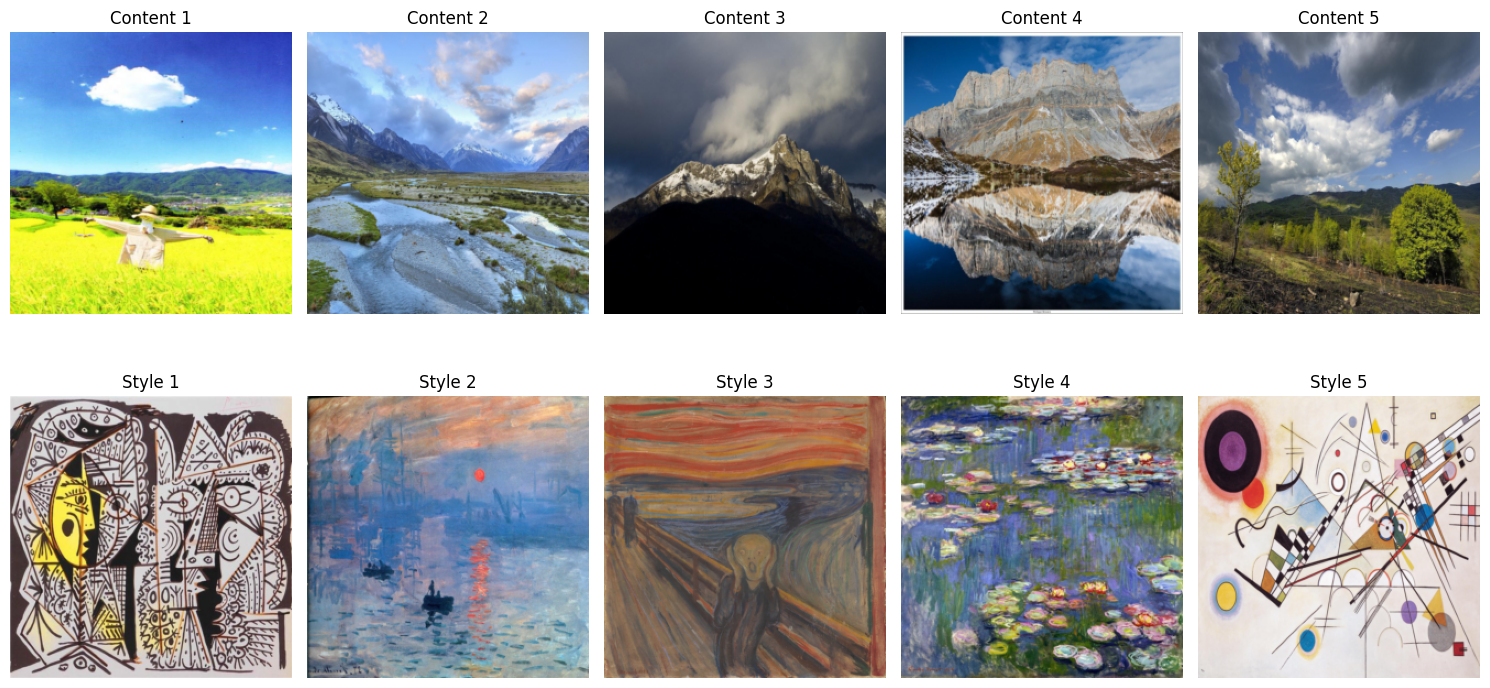

In [ ]:
# 6. Show Sample Images
plt.figure(figsize=(15, 8))

for i, path in enumerate(selected_content, 1):
    img = load_image(path, IMAGE_SIZE)
    plt.subplot(2, 5, i)
    imshow(img, f"Content {i}")

for i, path in enumerate(selected_style[:5], 6):
    img = load_image(path, IMAGE_SIZE)
    plt.subplot(2, 5, i)
    imshow(img, f"Style {i-5}")

plt.tight_layout()
plt.show()

## **7. Pre-trained VGG19 Model**
We load a pre-trained VGG19 model and freeze its weights to use it as a feature extractor.

In [ ]:
# 7. Load VGG19 Model
vgg = models.vgg19(weights=models.VGG19_Weights.DEFAULT).features.to(device).eval()

# Freeze model parameters
for param in vgg.parameters():
    param.requires_grad = False

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:06<00:00, 92.6MB/s]


## **8. Feature Extraction**
This section extracts feature maps from different layers of VGG19 to represent content and style features.

In [ ]:
# 8. Feature Extraction
style_layers = ['conv1_1', 'conv2_1', 'conv3_1', 'conv4_1', 'conv5_1']

def get_features(image, model):
    """Extract features from VGG layers"""
    layers = {
        '0': 'conv1_1',
        '5': 'conv2_1',
        '10': 'conv3_1',
        '19': 'conv4_1',
        '21': 'conv4_2',
        '28': 'conv5_1',
        '30': 'conv5_2'
    }

    features = {}
    x = image

    for name, layer in model._modules.items():
        x = layer(x)
        if name in layers:
            features[layers[name]] = x

    return features

## **9. Loss Functions**
We define the loss functions used in style transfer:
- Content Loss
- Style Loss (Gram Matrix)
- Total Variation Loss (for smoothness)

In [ ]:
# 9. Loss Functions
def gram_matrix(tensor):
    """Compute Gram matrix for style representation"""
    _, d, h, w = tensor.size()
    tensor = tensor.view(d, h * w)
    gram = torch.mm(tensor, tensor.t())
    return gram / (d * h * w)

def content_loss(gen_feat, content_feat):
    return torch.mean((gen_feat - content_feat) ** 2)

def style_loss(gen_feat, style_feat):
    gen_gram = gram_matrix(gen_feat)
    style_gram = gram_matrix(style_feat)
    return torch.mean((gen_gram - style_gram) ** 2)

def total_variation_loss(image):
    """Reduce noise and smooth output"""
    return (
        torch.sum(torch.abs(image[:, :, :, :-1] - image[:, :, :, 1:])) +
        torch.sum(torch.abs(image[:, :, :-1, :] - image[:, :, 1:, :]))
    )

## **10. Multi-Style Feature Blending**
This section blends multiple style images by averaging their feature representations.

In [ ]:
# 10. Multi-Style Blending
def blend_style_features(style_images, model):
    """Blend multiple style images"""
    all_style_features = [get_features(img, model) for img in style_images]
    blended = {}

    for layer in style_layers:
        blended[layer] = sum(features[layer] for features in all_style_features) / len(all_style_features)

    return blended

## **11. Neural Style Transfer Function**
This is the main optimization function where a generated image is updated iteratively to minimize content and style losses.

In [ ]:
# 11. Style Transfer Function
def run_style_transfer(
    content_image,
    style_image,
    model,
    epochs=200,
    alpha=1,
    beta=5e5,
    optimizer_type='adam',
    lr=0.002,
    use_scheduler=False,
    use_tv=False,
    tv_weight=1e-3,
    use_weighted_style=False,
    style_weights=None,
    content_layer='conv4_2',
    custom_style_features=None,
    experiment_name="Experiment"
):

    generated = content_image.clone().requires_grad_(True).to(device)

    content_features = get_features(content_image, model)

    if custom_style_features is not None:
        style_features = custom_style_features
    else:
        style_features = get_features(style_image, model)

    # Select optimizer
    if optimizer_type == 'adam':
        optimizer = optim.Adam([generated], lr=lr)
    elif optimizer_type == 'lbfgs':
        optimizer = optim.LBFGS([generated], lr=lr)
    else:
        raise ValueError("Unsupported optimizer type")

    # Learning rate scheduler
    scheduler = None
    if use_scheduler and optimizer_type == 'adam':
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.7)

    # Style weights
    if style_weights is None:
        style_weights = {layer: 1.0 for layer in style_layers}

    losses = []

    for i in range(epochs):

        def closure():
            optimizer.zero_grad()
            gen_features = get_features(generated, model)

            # Style loss
            s_loss = 0
            for layer in style_layers:
                weight = style_weights[layer] if use_weighted_style else 1.0
                s_loss += weight * style_loss(gen_features[layer], style_features[layer])

            # Content loss
            c_loss = content_loss(
                gen_features[content_layer],
                content_features[content_layer]
            )

            total_loss = alpha * c_loss + beta * s_loss

            # TV Loss
            if use_tv:
                total_loss += tv_weight * total_variation_loss(generated)

            total_loss.backward()
            return total_loss

        # Optimization step
        if optimizer_type == 'lbfgs':
            loss = optimizer.step(closure)
            loss_value = loss.item()
        else:
            loss = closure()
            optimizer.step()
            loss_value = loss.item()
            if scheduler:
                scheduler.step()

        losses.append(loss_value)

        if i % 50 == 0:
            print(f"{experiment_name} - Step {i}, Loss: {loss_value:.4f}")

    return generated.detach(), losses

## **12. Experiments and Comparisons**
In this section, we evaluate different configurations of the style transfer model to analyze performance improvements.


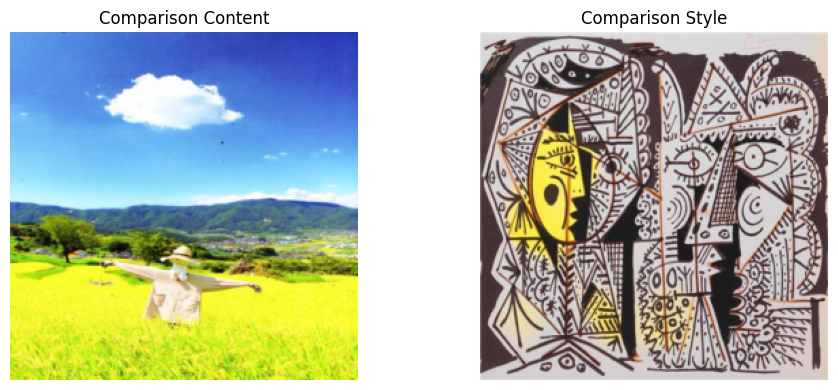

In [ ]:
# 12. Experiments and Comparisons

# Use one fixed content image and one fixed style image for all experiments
comparison_content = load_image(selected_content[0], IMAGE_SIZE)
comparison_style = load_image(selected_style[0], IMAGE_SIZE)

content_image = comparison_content
style_image = comparison_style

# Display the selected content and style images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
imshow(content_image, "Comparison Content")

plt.subplot(1, 2, 2)
imshow(style_image, "Comparison Style")

plt.tight_layout()
plt.show()

In [ ]:
# Run Different Experiments

# Baseline model
baseline_img, baseline_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=200,
    alpha=1,
    beta=5e5,
    optimizer_type='adam',
    lr=0.002,
    use_scheduler=False,
    use_tv=False,
    use_weighted_style=False,
    content_layer='conv4_2',
    experiment_name="Baseline"
)

Baseline - Step 0, Loss: 1561.4188
Baseline - Step 50, Loss: 955.6097
Baseline - Step 100, Loss: 675.8417
Baseline - Step 150, Loss: 533.0573


In [ ]:
# With Total Variation Loss
tv_img, tv_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=200,
    alpha=1,
    beta=5e5,
    optimizer_type='adam',
    lr=0.002,
    use_tv=True,
    tv_weight=1e-3,
    experiment_name="TV Loss"
)

TV Loss - Step 0, Loss: 1602.9193
TV Loss - Step 50, Loss: 1010.0353
TV Loss - Step 100, Loss: 743.3901
TV Loss - Step 150, Loss: 610.8544


In [ ]:
# With Learning Rate Scheduler
sched_img, sched_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=200,
    alpha=1,
    beta=5e5,
    optimizer_type='adam',
    lr=0.002,
    use_scheduler=True,
    experiment_name="Scheduler"
)

Scheduler - Step 0, Loss: 1561.4188
Scheduler - Step 50, Loss: 955.5320
Scheduler - Step 100, Loss: 675.5969
Scheduler - Step 150, Loss: 567.6237


In [ ]:
# Weighted Style Layers
weighted_img, weighted_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=200,
    alpha=1,
    beta=5e5,
    optimizer_type='adam',
    lr=0.002,
    use_weighted_style=True,
    style_weights={
        'conv1_1': 1.0,
        'conv2_1': 0.7,
        'conv3_1': 0.4,
        'conv4_1': 0.2,
        'conv5_1': 0.1
    },
    experiment_name="Weighted Style"
)

Weighted Style - Step 0, Loss: 606.8718
Weighted Style - Step 50, Loss: 415.6382
Weighted Style - Step 100, Loss: 312.1060
Weighted Style - Step 150, Loss: 254.4605


In [ ]:
# Using LBFGS optimizer
lbfgs_img, lbfgs_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=150,
    alpha=1,
    beta=5e5,
    optimizer_type='lbfgs',
    lr=1.0,
    experiment_name="LBFGS"
)

LBFGS - Step 0, Loss: 1561.4188
LBFGS - Step 50, Loss: 25.0808
LBFGS - Step 100, Loss: 24.6310


In [ ]:
# Changing style weight (beta)
weights_img, weights_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=200,
    alpha=1,
    beta=8e5,
    optimizer_type='adam',
    lr=0.002,
    experiment_name="Changed Beta"
)

Changed Beta - Step 0, Loss: 2498.2703
Changed Beta - Step 50, Loss: 1520.4382
Changed Beta - Step 100, Loss: 1071.0173
Changed Beta - Step 150, Loss: 841.6334


In [ ]:
# Changing content layer
content_layer_img, content_layer_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=200,
    alpha=1,
    beta=5e5,
    optimizer_type='adam',
    lr=0.002,
    content_layer='conv5_2',
    experiment_name="Changed Content Layer"
)

Changed Content Layer - Step 0, Loss: 1561.4188
Changed Content Layer - Step 50, Loss: 943.7740
Changed Content Layer - Step 100, Loss: 661.3844
Changed Content Layer - Step 150, Loss: 517.0398


In [ ]:
# Load second style image (for blending)
style_image_2 = load_image(selected_style[1], IMAGE_SIZE)

# Blend features from two style images
blended_features = blend_style_features([style_image, style_image_2], vgg)

multi_style_img, multi_style_losses = run_style_transfer(
    content_image,
    style_image,
    vgg,
    custom_style_features=blended_features,
    experiment_name="Multi Style"
)

Multi Style - Step 0, Loss: 187.6326
Multi Style - Step 50, Loss: 97.3719
Multi Style - Step 100, Loss: 72.9927
Multi Style - Step 150, Loss: 61.7318


In [ ]:
# Lower learning rate
lr_img, lr_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=200,
    alpha=1,
    beta=5e5,
    optimizer_type='adam',
    lr=0.001,
    experiment_name="Lower LR"
)

Lower LR - Step 0, Loss: 1561.4188
Lower LR - Step 50, Loss: 1216.8351
Lower LR - Step 100, Loss: 917.4062
Lower LR - Step 150, Loss: 760.6988


In [ ]:
# Stronger style weight
strong_style_img, strong_style_losses = run_style_transfer(
    content_image, style_image, vgg,
    epochs=200,
    alpha=1,
    beta=1e6,
    optimizer_type='adam',
    lr=0.002,
    experiment_name="Strong Style"
)

Strong Style - Step 0, Loss: 3122.8376
Strong Style - Step 50, Loss: 1897.9531
Strong Style - Step 100, Loss: 1335.4442
Strong Style - Step 150, Loss: 1047.9025


In [ ]:
# Smaller image size experiment
content_image_128 = load_image(selected_content[0], 128)
style_image_128 = load_image(selected_style[0], 128)

imgsize_img, imgsize_losses = run_style_transfer(
    content_image_128, style_image_128, vgg,
    epochs=200,
    alpha=1,
    beta=5e5,
    optimizer_type='adam',
    lr=0.002,
    experiment_name="Image Size 128"
)

Image Size 128 - Step 0, Loss: 860.0800
Image Size 128 - Step 50, Loss: 563.6074
Image Size 128 - Step 100, Loss: 411.8989
Image Size 128 - Step 150, Loss: 333.7963


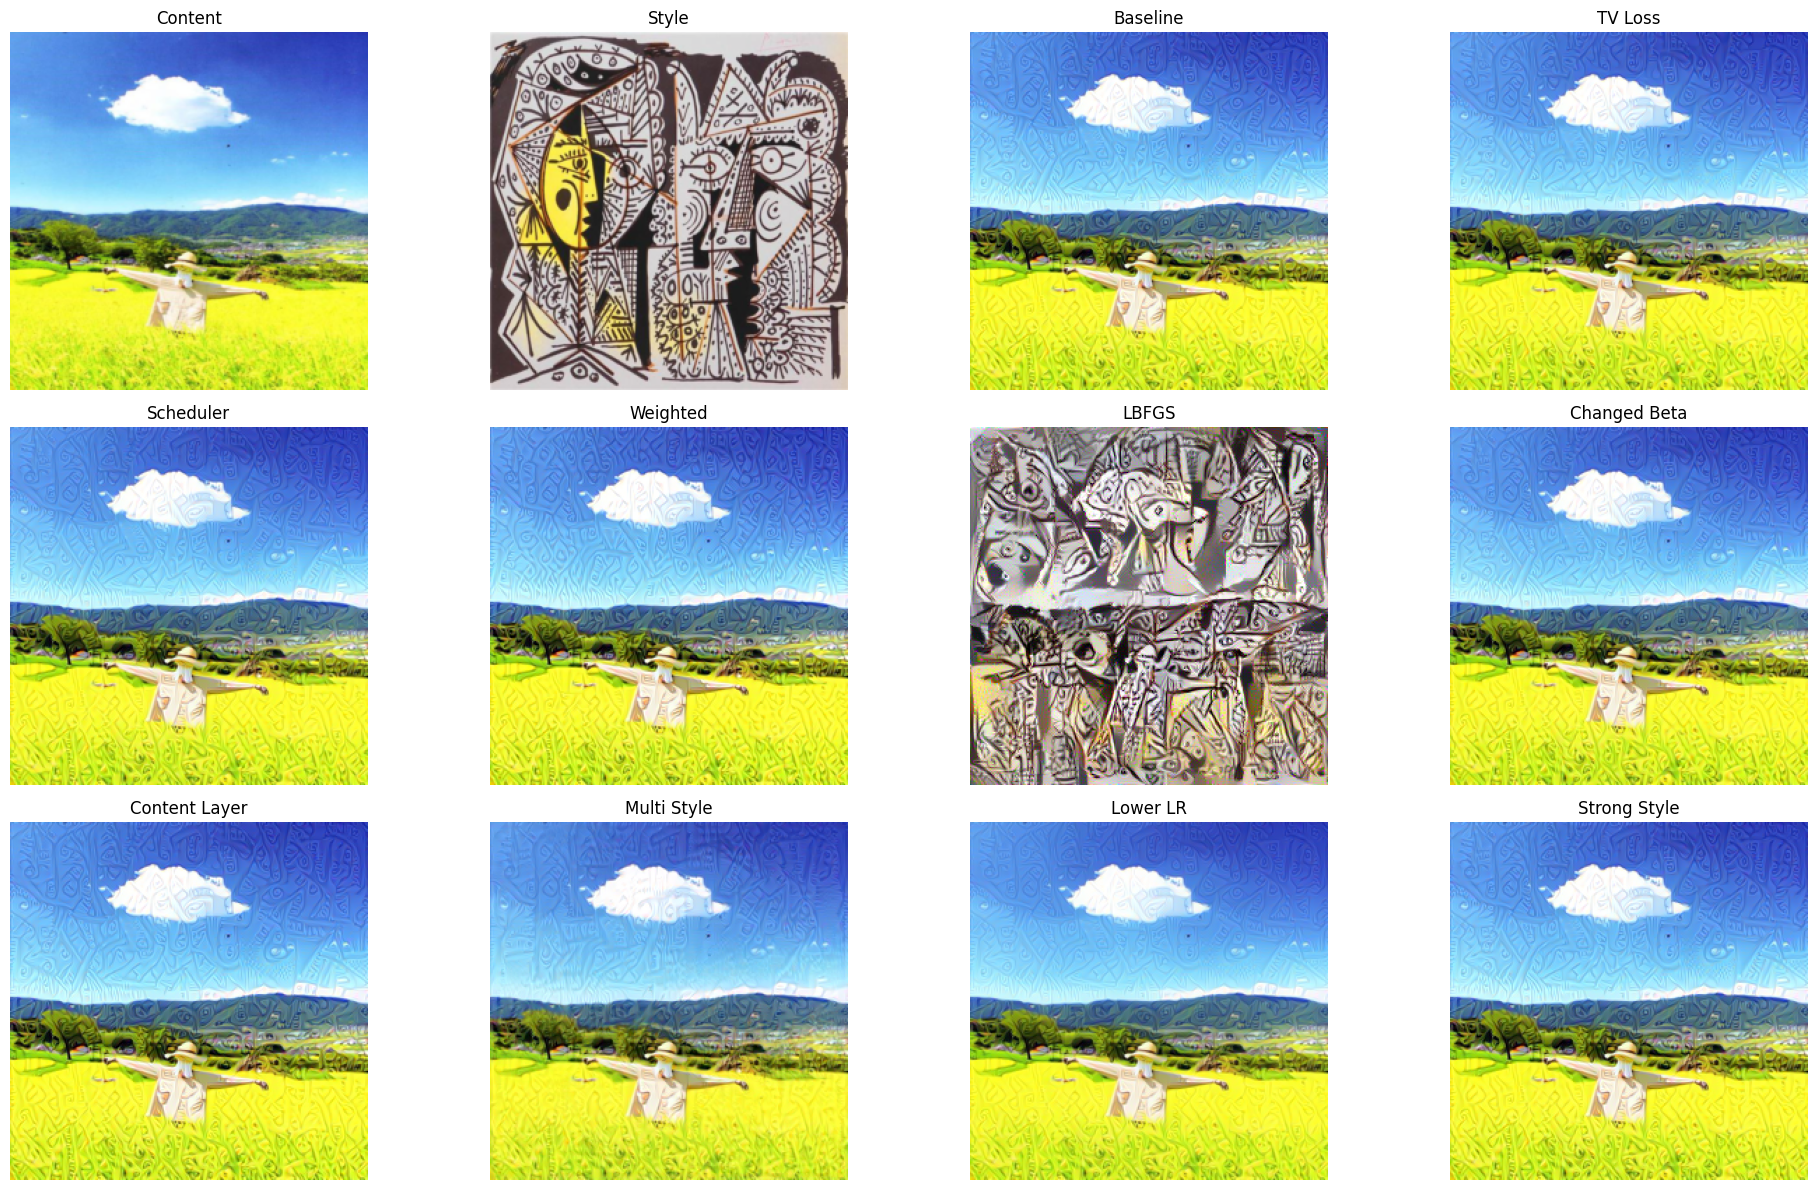

In [ ]:
# Visual Comparison
results = [
    ("Content", content_image),
    ("Style", style_image),
    ("Baseline", baseline_img),
    ("TV Loss", tv_img),
    ("Scheduler", sched_img),
    ("Weighted", weighted_img),
    ("LBFGS", lbfgs_img),
    ("Changed Beta", weights_img),
    ("Content Layer", content_layer_img),
    ("Multi Style", multi_style_img),
    ("Lower LR", lr_img),
    ("Strong Style", strong_style_img)
]

plt.figure(figsize=(20, 12))

for i, (title, img) in enumerate(results, 1):
    plt.subplot(3, 4, i)
    imshow(img, title)

plt.tight_layout()
plt.show()

## **Loss Curves Analysis**
This section compares the training loss of all experiments to evaluate convergence behavior.

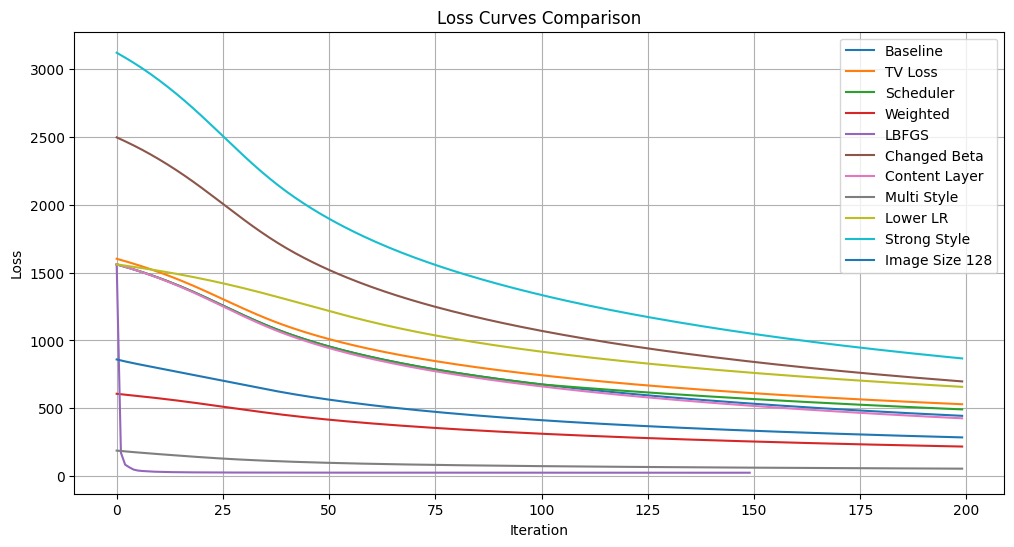

In [ ]:
# Loss Curves Comparison
plt.figure(figsize=(12,6))

plt.plot(baseline_losses, label='Baseline')
plt.plot(tv_losses, label='TV Loss')
plt.plot(sched_losses, label='Scheduler')
plt.plot(weighted_losses, label='Weighted')
plt.plot(lbfgs_losses, label='LBFGS')
plt.plot(weights_losses, label='Changed Beta')
plt.plot(content_layer_losses, label='Content Layer')
plt.plot(multi_style_losses, label='Multi Style')
plt.plot(lr_losses, label='Lower LR')
plt.plot(strong_style_losses, label='Strong Style')
plt.plot(imgsize_losses, label='Image Size 128')

plt.title("Loss Curves Comparison")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Final Loss Ranking
final_losses = {
    "Baseline": baseline_losses[-1],
    "TV Loss": tv_losses[-1],
    "Scheduler": sched_losses[-1],
    "Weighted Style": weighted_losses[-1],
    "LBFGS": lbfgs_losses[-1],
    "Changed Beta": weights_losses[-1],
    "Content Layer": content_layer_losses[-1],
    "Multi Style": multi_style_losses[-1],
    "Lower LR": lr_losses[-1],
    "Strong Style": strong_style_losses[-1],
    "Image Size 128": imgsize_losses[-1]
}

for model, loss in sorted(final_losses.items(), key=lambda x: x[1]):
    print(f"{model}: {loss:.4f}")

LBFGS: 24.4785
Multi Style: 54.5269
Weighted Style: 217.6866
Image Size 128: 285.0638
Content Layer: 425.9370
Baseline: 444.1620
Scheduler: 491.6587
TV Loss: 529.8054
Lower LR: 657.9021
Changed Beta: 698.1506
Strong Style: 867.6779


## **13. Final Results**
We generate final stylized images for multiple content images using the best configuration.

In [ ]:
# Final Outputs on Multiple Content Images
all_outputs = []
best_style = style_image

for i, path in enumerate(selected_content, 1):
    current_content = load_image(path, IMAGE_SIZE)

    output_img, _ = run_style_transfer(
        current_content, best_style, vgg,
        epochs=500,
        alpha=1,
        beta=5e5,
        optimizer_type='adam',
        lr=0.002,
        use_weighted_style=True,
        style_weights={
            'conv1_1': 1.0,
            'conv2_1': 0.7,
            'conv3_1': 0.4,
            'conv4_1': 0.2,
            'conv5_1': 0.1
        },
        experiment_name=f"Final Output {i}"
    )

    all_outputs.append((current_content, output_img))

Final Output 1 - Step 0, Loss: 606.8718
Final Output 1 - Step 50, Loss: 415.6519
Final Output 1 - Step 100, Loss: 312.1387
Final Output 1 - Step 150, Loss: 254.4489
Final Output 1 - Step 200, Loss: 217.0195
Final Output 1 - Step 250, Loss: 190.4102
Final Output 1 - Step 300, Loss: 170.1579
Final Output 1 - Step 350, Loss: 153.9398
Final Output 1 - Step 400, Loss: 140.4168
Final Output 1 - Step 450, Loss: 128.8887
Final Output 2 - Step 0, Loss: 602.7570
Final Output 2 - Step 50, Loss: 405.2217
Final Output 2 - Step 100, Loss: 287.3281
Final Output 2 - Step 150, Loss: 223.0837
Final Output 2 - Step 200, Loss: 181.2073
Final Output 2 - Step 250, Loss: 152.4846
Final Output 2 - Step 300, Loss: 131.8104
Final Output 2 - Step 350, Loss: 116.3311
Final Output 2 - Step 400, Loss: 104.2398
Final Output 2 - Step 450, Loss: 94.4406
Final Output 3 - Step 0, Loss: 662.9562
Final Output 3 - Step 50, Loss: 422.2029
Final Output 3 - Step 100, Loss: 295.8152
Final Output 3 - Step 150, Loss: 228.7451
Fi

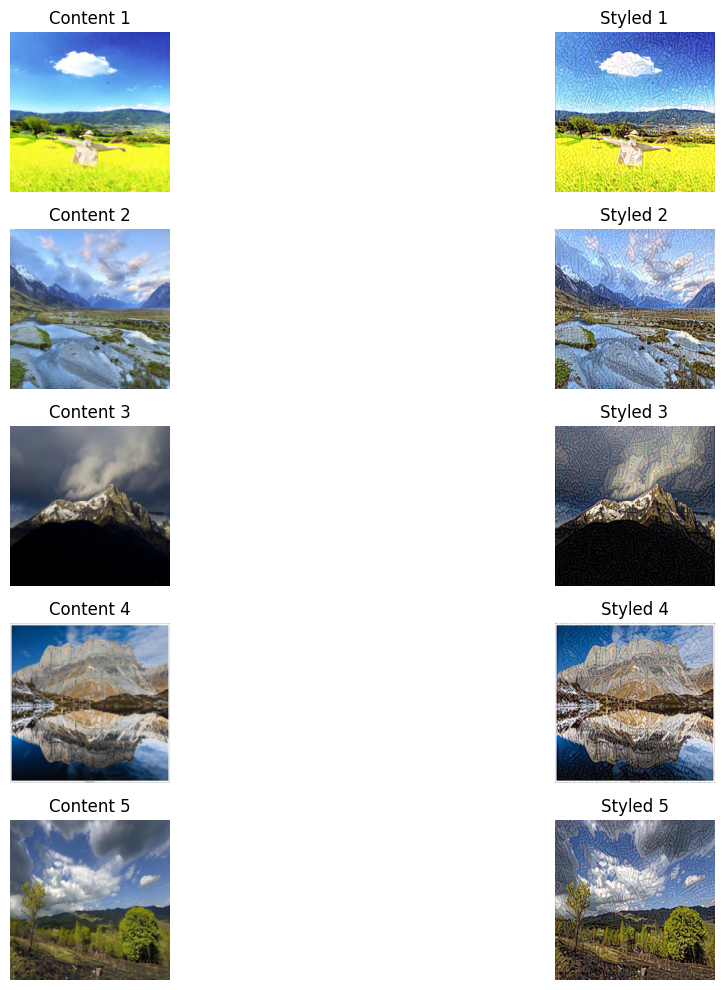

In [ ]:
# 13. Display final results
plt.figure(figsize=(15,10))

for i, (content_img, output_img) in enumerate(all_outputs, 1):
    plt.subplot(len(all_outputs), 2, 2*i - 1)
    imshow(content_img, f"Content {i}")

    plt.subplot(len(all_outputs), 2, 2*i)
    imshow(output_img, f"Styled {i}")

plt.tight_layout()
plt.show()